# Prédiction du churn client — IBM Telco

**Objectif.** Classer les clients susceptibles de résilier et prioriser une campagne de rétention. Ce notebook est le rendu principal du projet : il montre les données, les expériences de preprocessing, les quatre familles de modèles, la recherche d'hyperparamètres, les métriques sur un test réservé, les explications et le ciblage.

**Protocole.** Split stratifié 80/20 avec graine 42. Tous les traitements et réglages sont appris dans les plis d'entraînement. Le modèle est choisi par PR-AUC en validation croisée à cinq plis. Le seuil de décision est choisi sur des prédictions hors pli du train. Le test est consulté une fois, à la fin. Les résultats ci-dessous sont calculés lors de l'exécution du notebook ; aucun score n'est prérempli.

Source : [IBM, copie officielle du CSV](https://github.com/IBM/telco-customer-churn-on-icp4d/blob/master/data/Telco-Customer-Churn.csv) ; [fiche Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn). Il s'agit de données d'exemple, sans historique temporel exploitable pour un test prospectif.

## 1. Environnement et données

Depuis la racine du dépôt : `python -m pip install -r requirements.txt`, puis `jupyter lab`. Le premier chargement télécharge le CSV officiel IBM dans `data/`. Aucun identifiant client n'entre dans les variables du modèle.

In [1]:
from pathlib import Path
import os, sys
if Path.cwd().name == "notebooks": os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
    average_precision_score, precision_recall_curve
)
from src.churn import (
    RANDOM_STATE, ID_COLUMN, TARGET, load_data, split_features,
    select_model, choose_threshold, evaluate
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
data = load_data()
print(f"{len(data):,} clients ; {data.shape[1]} colonnes ; taux de churn : {(data[TARGET] == 'Yes').mean():.1%}")
display(data.head())
display(data.dtypes.to_frame("type").T)

7,043 clients ; 21 colonnes ; taux de churn : 26.5%


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
type,str,str,int64,str,str,int64,str,str,str,str,str,str,str,str,str,str,str,str,float64,float64,str


### Qualité des données et exploration

`TotalCharges` comporte des chaînes vides : la conversion crée des valeurs manquantes qui sont imputées dans la pipeline. Les lignes ne sont pas supprimées. Les graphiques descriptifs restent exploratoires ; les décisions de modèle reposent sur la validation croisée.

In [2]:
quality = pd.DataFrame({
    "manquants": data.isna().sum(),
    "modalites": data.nunique(dropna=True),
    "type": data.dtypes.astype(str),
}).sort_values("manquants", ascending=False)
display(quality)
print("Identifiants dupliqués :", data[ID_COLUMN].duplicated().sum())
print("Churn :")
display(data[TARGET].value_counts().rename_axis("classe").to_frame("effectif"))

,manquants,modalites,type
TotalCharges,11,6530,float64
gender,0,2,str
SeniorCitizen,0,2,int64
Partner,0,2,str
customerID,0,7043,str
Dependents,0,2,str
tenure,0,73,int64
MultipleLines,0,3,str
PhoneService,0,2,str
OnlineSecurity,0,3,str


Identifiants dupliqués : 0
Churn :


,effectif
classe,
No,5174
Yes,1869


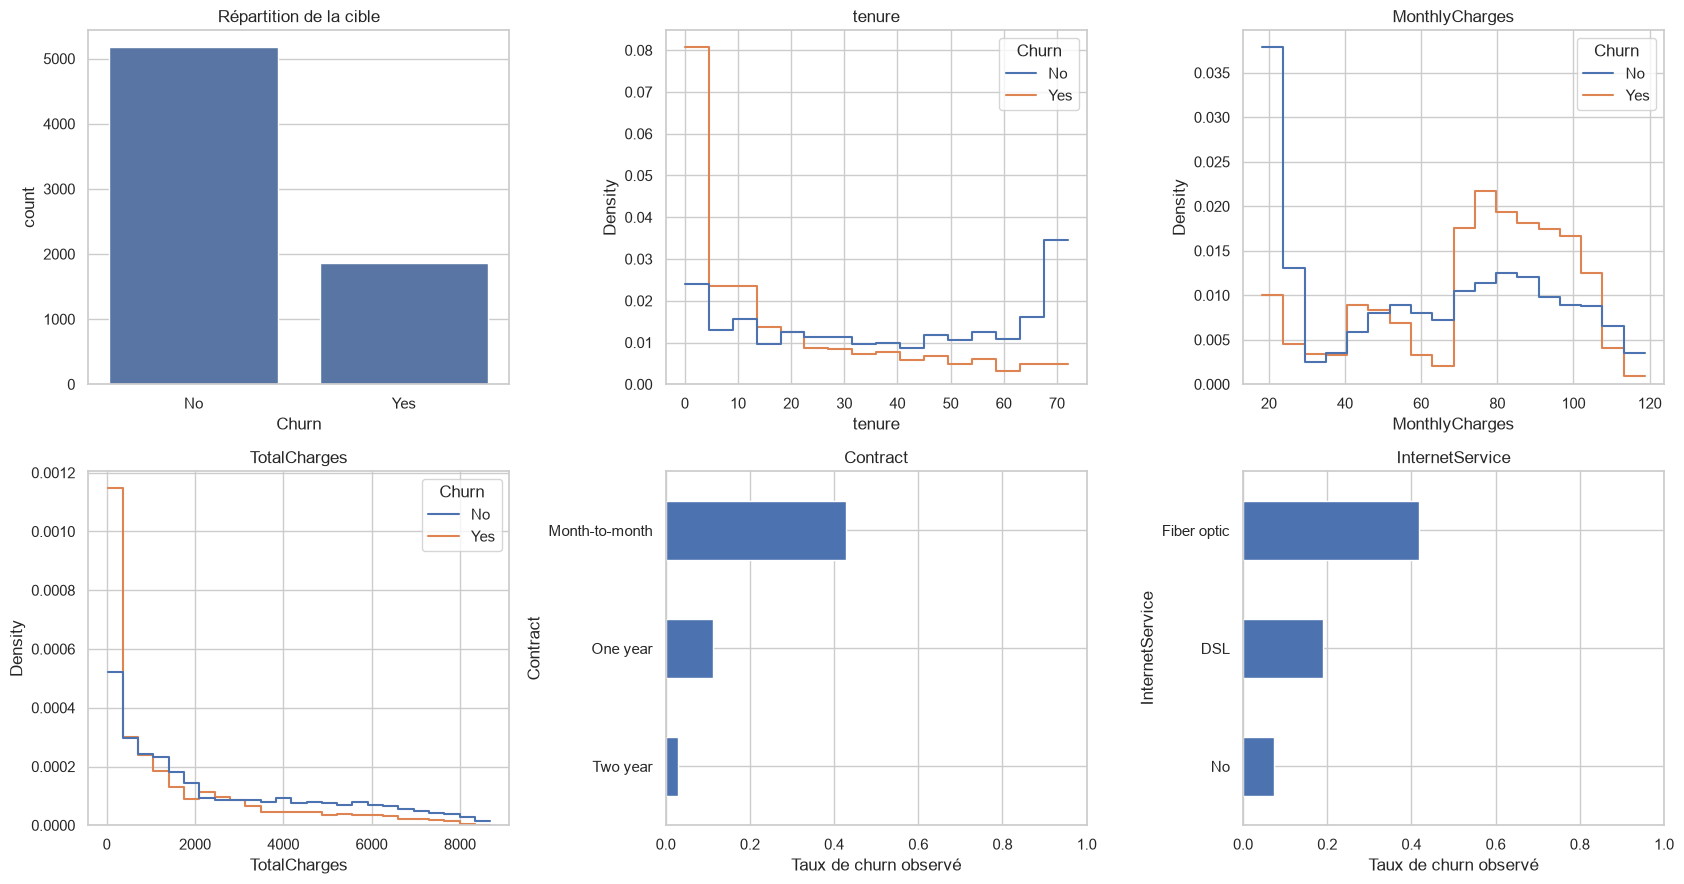

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
sns.countplot(data=data, x=TARGET, ax=axes[0, 0])
axes[0, 0].set_title("Répartition de la cible")
for ax, col in zip([axes[0, 1], axes[0, 2], axes[1, 0]], ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.histplot(data=data, x=col, hue=TARGET, stat="density", common_norm=False,
                 element="step", fill=False, ax=ax)
    ax.set_title(col)
for ax, col in zip([axes[1, 1], axes[1, 2]], ["Contract", "InternetService"]):
    rate = data.groupby(col, observed=True)[TARGET].apply(lambda s: (s == "Yes").mean()).sort_values()
    rate.plot.barh(ax=ax)
    ax.set_xlim(0, 1)
    ax.set_xlabel("Taux de churn observé")
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 2. Séparation et expériences

Les imputations `median` et `constant=0`, ainsi que la standardisation activée ou non, sont testées dans la validation croisée. Les catégories sont imputées puis encodées par one-hot ; une catégorie inconnue au scoring est tolérée. Les quatre modèles utilisent le même découpage. La métrique de sélection est la **PR-AUC**, utile avec une classe positive minoritaire. Les grilles sont volontairement compactes pour rester exécutables sur un ordinateur personnel.

In [4]:
x, y = split_features(data)
x_train, x_test, y_train, y_test, ids_train, ids_test = train_test_split(
    x, y, data[ID_COLUMN], test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Train :", x_train.shape, " Test :", x_test.shape)
print("Taux de churn train/test :", round(y_train.mean(), 4), round(y_test.mean(), 4))

Train : (5634, 19)  Test : (1409, 19)
Taux de churn train/test : 0.2654 0.2654


In [5]:
best_model, comparison, selection = select_model(x_train, y_train, folds=5, n_jobs=-1)
display(comparison.style.format({"cv_pr_auc": "{:.4f}"}))
print("Meilleure combinaison :", json.dumps(selection, ensure_ascii=False, indent=2))

C:\Users\evanf\Documents\Pr-diction-du-churn-client\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,preprocessing,modele,cv_pr_auc,params
2,median+standard,XGBoost,0.6706,"{'model__learning_rate': 0.03, 'model__max_depth': 4, 'model__n_estimators': 200}"
6,median+sans_echelle,XGBoost,0.6706,"{'model__learning_rate': 0.03, 'model__max_depth': 4, 'model__n_estimators': 200}"
10,zero+standard,XGBoost,0.6703,"{'model__learning_rate': 0.03, 'model__max_depth': 4, 'model__n_estimators': 200}"
11,zero+standard,LightGBM,0.6672,"{'model__learning_rate': 0.03, 'model__n_estimators': 200, 'model__num_leaves': 7}"
3,median+standard,LightGBM,0.6667,"{'model__learning_rate': 0.03, 'model__n_estimators': 200, 'model__num_leaves': 7}"
7,median+sans_echelle,LightGBM,0.6657,"{'model__learning_rate': 0.03, 'model__n_estimators': 200, 'model__num_leaves': 7}"
4,median+sans_echelle,Logistic Regression,0.6621,"{'model__C': 0.1, 'model__class_weight': None}"
5,median+sans_echelle,Random Forest,0.6618,"{'model__max_depth': 10, 'model__min_samples_leaf': 5, 'model__n_estimators': 400}"
1,median+standard,Random Forest,0.6617,"{'model__max_depth': 10, 'model__min_samples_leaf': 5, 'model__n_estimators': 400}"
8,zero+standard,Logistic Regression,0.6615,"{'model__C': 1.0, 'model__class_weight': None}"


Meilleure combinaison : {
  "preprocessing": "median+standard",
  "modele": "XGBoost",
  "cv_pr_auc": 0.6705723280690509,
  "params": {
    "model__learning_rate": 0.03,
    "model__max_depth": 4,
    "model__n_estimators": 200
  }
}


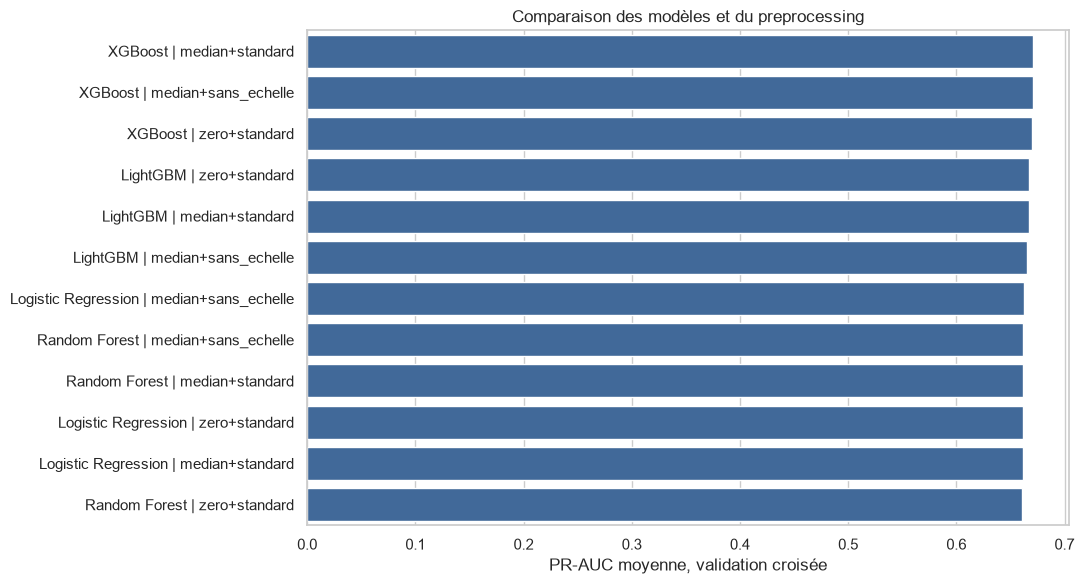

In [6]:
plt.figure(figsize=(11, 6))
chart = comparison.copy()
chart["experience"] = chart["modele"] + " | " + chart["preprocessing"]
sns.barplot(data=chart, y="experience", x="cv_pr_auc", color="#3268a8")
plt.xlabel("PR-AUC moyenne, validation croisée")
plt.ylabel("")
plt.title("Comparaison des modèles et du preprocessing")
plt.tight_layout()
plt.show()

### Seuil choisi sur le train

Le seuil 0,5 est une convention. Ici, le F1 est optimisé sur des probabilités hors pli du train ; il ne dépend pas du jeu test. En production, un seuil fondé sur la valeur économique et la capacité de contact serait préférable.

,seuil,precision,rappel,f1
8,0.350,0.584,0.704,0.639
7,0.325,0.561,0.740,0.638
6,0.300,0.543,0.766,0.635
9,0.375,0.597,0.675,0.634
5,0.275,0.526,0.793,0.633
10,0.400,0.614,0.645,0.629
11,0.425,0.634,0.623,0.629
4,0.250,0.511,0.813,0.628
3,0.225,0.494,0.840,0.623
12,0.450,0.649,0.597,0.622


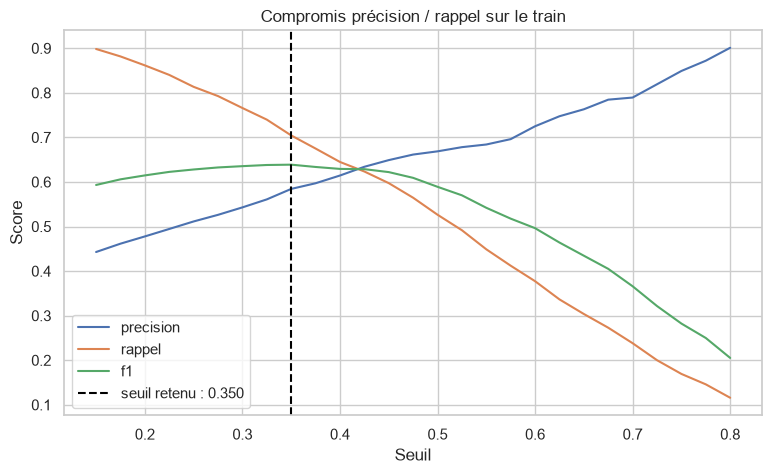

In [7]:
threshold, threshold_table = choose_threshold(best_model, x_train, y_train, folds=5)
display(threshold_table.sort_values("f1", ascending=False).head(10).style.format(
    {"seuil": "{:.3f}", "precision": "{:.3f}", "rappel": "{:.3f}", "f1": "{:.3f}"}
))
fig, ax = plt.subplots(figsize=(9, 5))
for metric in ["precision", "rappel", "f1"]:
    ax.plot(threshold_table["seuil"], threshold_table[metric], label=metric)
ax.axvline(threshold, color="black", linestyle="--", label=f"seuil retenu : {threshold:.3f}")
ax.set(xlabel="Seuil", ylabel="Score", title="Compromis précision / rappel sur le train")
ax.legend()
plt.show()

## 3. Évaluation finale sur le test réservé

Cette section ne modifie plus le modèle ni le seuil. La matrice de confusion suit l'ordre `[[vrais négatifs, faux positifs], [faux négatifs, vrais positifs]]`. La PR-AUC de référence d'un classement aléatoire correspond approximativement à la prévalence du churn.

,test
roc_auc,0.846463
pr_auc,0.659321
accuracy,0.776437
balanced_accuracy,0.753907
precision,0.562900
recall,0.705882
f1,0.626335
threshold,0.350000
test_rows,1409.000000


PR-AUC de référence (prévalence) : 0.2654


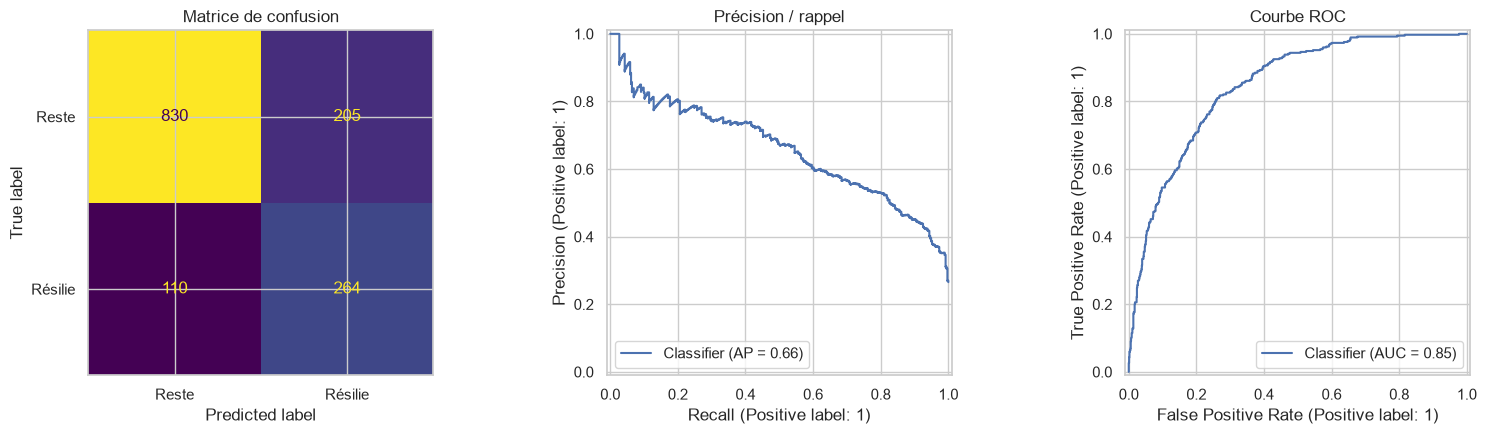

In [8]:
test_metrics = evaluate(best_model, x_test, y_test, threshold)
display(pd.Series({k: v for k, v in test_metrics.items() if k != "confusion_matrix"}, name="test").to_frame())
prob_test = best_model.predict_proba(x_test)[:, 1]
print("PR-AUC de référence (prévalence) :", round(y_test.mean(), 4))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, prob_test >= threshold, ax=axes[0],
                                       display_labels=["Reste", "Résilie"], colorbar=False)
PrecisionRecallDisplay.from_predictions(y_test, prob_test, ax=axes[1])
RocCurveDisplay.from_predictions(y_test, prob_test, ax=axes[2])
axes[0].set_title("Matrice de confusion")
axes[1].set_title("Précision / rappel")
axes[2].set_title("Courbe ROC")
plt.tight_layout()
plt.show()

### Ciblage à capacité fixe

La campagne contacte les clients avec les probabilités les plus élevées. `precision_at_k` mesure la part de churners observés parmi les contactés et `recall_at_k` la part de churners capturés. Ce calcul sur test illustre le classement ; le taux de succès réel d'une campagne ne peut pas être déduit de ce dataset observé.

In [9]:
ranking = pd.DataFrame({
    "customerID": ids_test.to_numpy(),
    "churn_observe": y_test.to_numpy(),
    "probabilite_churn": prob_test,
}).sort_values("probabilite_churn", ascending=False).reset_index(drop=True)
rows = []
for fraction in [0.05, 0.10, 0.20, 0.30]:
    k = max(1, int(np.ceil(len(ranking) * fraction)))
    captured = int(ranking.head(k)["churn_observe"].sum())
    precision = captured / k
    recall = captured / int(y_test.sum())
    rows.append({"part_contactee": fraction, "clients": k, "churners_captures": captured,
                 "precision_at_k": precision, "recall_at_k": recall,
                 "lift": precision / y_test.mean()})
targeting = pd.DataFrame(rows)
display(targeting.style.format({"part_contactee": "{:.0%}", "precision_at_k": "{:.1%}",
                                "recall_at_k": "{:.1%}", "lift": "{:.2f}x"}))
display(ranking.head(20))

,part_contactee,clients,churners_captures,precision_at_k,recall_at_k,lift
0,5%,71,57,80.3%,15.2%,3.02x
1,10%,141,106,75.2%,28.3%,2.83x
2,20%,282,189,67.0%,50.5%,2.52x
3,30%,423,246,58.2%,65.8%,2.19x


,customerID,churn_observe,probabilite_churn
0,5178-LMXOP,1,0.929081
1,0295-PPHDO,1,0.923775
2,1069-XAIEM,1,0.919382
3,9248-OJYKK,1,0.898550
4,5167-ZFFMM,1,0.895426
5,2609-IAICY,1,0.892675
6,6861-XWTWQ,1,0.883229
7,7181-BQYBV,1,0.876672
8,0655-RBDUG,1,0.870523
9,4415-IJZTP,1,0.862567


### Simulation économique paramétrable

**Hypothèses illustratives**, à remplacer par des données métier : coût d'un contact, marge mensuelle, durée de rétention additionnelle et probabilité qu'un client à risque accepte l'offre. Le gain affiché est une *valeur attendue sous hypothèses*, pas une estimation causale : aucune expérimentation randomisée ne permet ici d'observer l'effet de l'offre.

In [10]:
cout_contact = 5.0
marge_mensuelle = 25.0
mois_retenus = 6
taux_sauvetage_hypothetique = 0.15
k = int(np.ceil(len(ranking) * 0.20))
cibles = ranking.head(k).copy()
cibles["valeur_attendue_eur"] = (
    cibles["probabilite_churn"] * taux_sauvetage_hypothetique
    * marge_mensuelle * mois_retenus - cout_contact
)
print(f"Scénario top 20 % : {k} contacts, valeur attendue illustrative = "
      f"{cibles['valeur_attendue_eur'].sum():,.0f} €")
display(cibles.head(15))

Scénario top 20 % : 282 contacts, valeur attendue illustrative = 2,850 €


,customerID,churn_observe,probabilite_churn,valeur_attendue_eur
0,5178-LMXOP,1,0.929081,15.904318
1,0295-PPHDO,1,0.923775,15.784931
2,1069-XAIEM,1,0.919382,15.686104
3,9248-OJYKK,1,0.898550,15.217377
4,5167-ZFFMM,1,0.895426,15.147079
5,2609-IAICY,1,0.892675,15.085178
6,6861-XWTWQ,1,0.883229,14.872646
7,7181-BQYBV,1,0.876672,14.725132
8,0655-RBDUG,1,0.870523,14.586775
9,4415-IJZTP,1,0.862567,14.407761


## 4. Explications SHAP

SHAP décrit l'influence des variables **sur la prédiction du modèle**. Il ne prouve pas qu'une modification de contrat ou de service réduira le churn. Pour garder une comparaison lisible entre les quatre modèles, l'analyse porte sur la matrice transformée d'un échantillon du test. Selon la version de SHAP, le calcul peut prendre quelques minutes.

C:\Users\evanf\Documents\Pr-diction-du-churn-client\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,SHAP absolu moyen
cat__Contract_Month-to-month,0.750526
num__tenure,0.425714
num__MonthlyCharges,0.280908
cat__OnlineSecurity_No,0.248510
cat__InternetService_Fiber optic,0.193421
cat__TechSupport_No,0.173915
cat__PaymentMethod_Electronic check,0.158114
cat__Contract_Two year,0.122996
num__TotalCharges,0.122655
cat__PaperlessBilling_No,0.112054


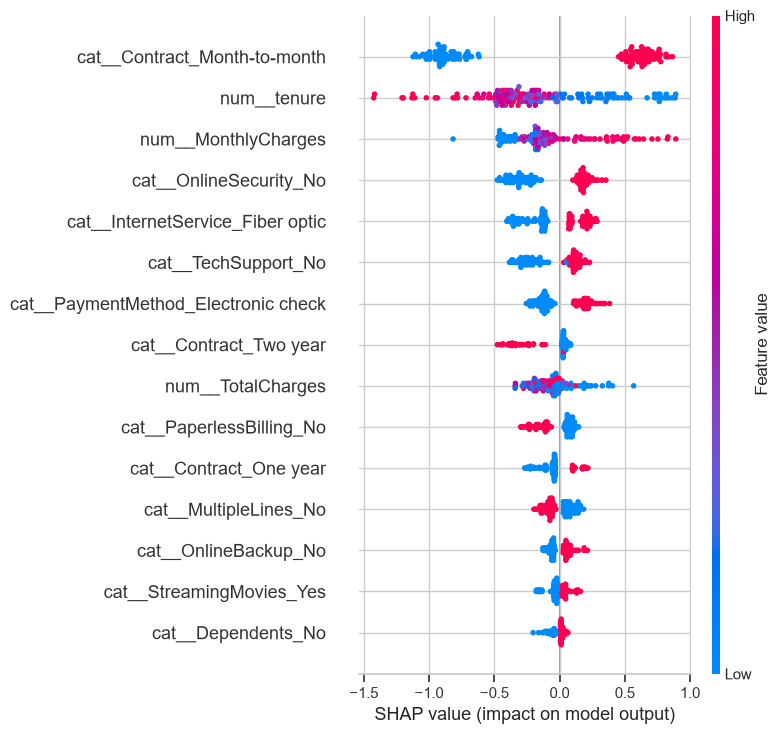

In [11]:
import shap
sample = x_test.sample(min(150, len(x_test)), random_state=RANDOM_STATE)
transformer = best_model.named_steps["preprocess"]
encoded = transformer.transform(sample)
feature_names = transformer.get_feature_names_out()
if hasattr(encoded, "toarray"):
    encoded = encoded.toarray()
background = x_train.sample(min(100, len(x_train)), random_state=RANDOM_STATE)
background_encoded = transformer.transform(background)
if hasattr(background_encoded, "toarray"):
    background_encoded = background_encoded.toarray()
model = best_model.named_steps["model"]
try:
    if selection["modele"] in {"Random Forest", "XGBoost", "LightGBM"}:
        explainer = shap.TreeExplainer(model)
        values = explainer(encoded)
    elif selection["modele"] == "Logistic Regression":
        explainer = shap.LinearExplainer(model, background_encoded)
        values = explainer(encoded)
    else:
        raise ValueError("Modèle SHAP non pris en charge")
    shap_values = values.values
    if shap_values.ndim == 3:
        shap_values = shap_values[:, :, 1]
    importance = pd.Series(np.abs(shap_values).mean(axis=0), index=feature_names)
    display(importance.sort_values(ascending=False).head(20).to_frame("SHAP absolu moyen"))
    shap.summary_plot(shap_values, encoded, feature_names=feature_names, show=False,
                      max_display=15)
    plt.tight_layout()
    plt.show()
except Exception as exc:
    warnings.warn(f"SHAP indisponible pour cette combinaison de versions : {exc}")

## 5. Artefacts et usage MLOps

La commande `python -m src.churn train` reproduit la sélection, l'évaluation et l'enregistrement du pipeline avec ses statistiques d'imputation, son encodeur, son modèle et son seuil. `score` applique cet artefact à un nouveau CSV. Les métriques, comparaisons et prédictions de test sont conservées dans `artifacts/`. Le notebook fait les mêmes expériences et fournit les visuels de diagnostic.

In [12]:
from pathlib import Path
import joblib
artifact_dir = Path("artifacts")
artifact_dir.mkdir(exist_ok=True)
joblib.dump({"pipeline": best_model, "threshold": threshold, "features": list(x.columns)},
            artifact_dir / "model.joblib")
comparison.to_csv(artifact_dir / "model_comparison.csv", index=False)
threshold_table.to_csv(artifact_dir / "thresholds.csv", index=False)
ranking.to_csv(artifact_dir / "test_predictions.csv", index=False)
report = {"dataset_rows": len(data), "train_rows": len(x_train),
          "selection": selection, "test": test_metrics}
(artifact_dir / "metrics.json").write_text(
    json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Artefacts enregistrés dans", artifact_dir.resolve())

Artefacts enregistrés dans C:\Users\evanf\Documents\Pr-diction-du-churn-client\artifacts


## Limites et suites

- Le jeu de données est un exemple IBM. Les performances ne se transposent pas directement à une vraie clientèle.
- Le découpage aléatoire mesure une généralisation interne. Avec de nouvelles données, utiliser une période ultérieure, surveiller le changement de distribution et réentraîner si nécessaire.
- Les données ne décrivent pas les offres de rétention et leurs effets. Le ciblage doit être validé par un test A/B avant de chiffrer un gain réel.
- Vérifier calibration, équité et stabilité des performances par segment avant toute décision automatisée.